# Midterm Project: Object Sorting (Computer Vision)
**Course:** Computer Vision  |  **Specialization:** Object Sorting  |  **Section:** BS Computer Science – 4A
**Group:** Alba, Bacsain, Bagaporo, Nonato, Palacios, Prestado

This notebook runs the complete Midterm pipeline: **Camera/Image → Preprocessing → CNN model → Recognition → Visual output**.

**Dataset:** Single, S., Iranmanesh, S., & Raad, R. (2023). *RealWaste* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5SS4G (CC BY 4.0)

## Step 1. Setup and dataset

In [1]:
%pip install tensorflow opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/73.8 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/73.8 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/73.8 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/73.8 MB 619.9 kB/s eta 0:01:59

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/73.8 MB 619.9 kB/s eta 0:01:59

...

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 73.4/73.8 MB 595.3 kB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 73.4/73.8 MB 595.3 kB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 73.7/73.8 MB 588.2 kB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 583.6 kB/s  0:02:11


Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, sys, json, random, shutil, zipfile, time, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------- Settings (change here if your group chose differently) ----------------
CLASSES      = ['Cardboard', 'Glass', 'Metal', 'Paper', 'Plastic']   # 3-5 classes allowed at Midterm
SPLIT        = (0.70, 0.15, 0.15)       # train / validation / test
IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32
SEED         = 42
EPOCHS_HEAD  = 12                       # train new top layers
EPOCHS_FT    = 10                       # fine-tune upper layers
CONF_THRESH  = 0.60                     # below this the demo says "Uncertain"
WEIGHTS      = 'imagenet'               # pre-trained weights (MobileNetV2)
# -----------------------------------------------------------------------------------------

# Fix every source of randomness to SEED so the split, shuffling and augmentation
# are reproducible between runs.
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__, '| OpenCV', cv2.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'none (training will be slower; use Runtime > Change runtime type > T4 GPU)')

I0000 00:00:1792216644.931639 1018256 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792216644.973424 1018256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792216646.263059 1018256 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | OpenCV 5.0.0
GPU: none (training will be slower; use Runtime > Change runtime type > T4 GPU)


E0000 00:00:1792216647.163154 1018256 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792216647.163481 1019448 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792216647.182208 1018256 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


### Provide the dataset zip
Choose **one** option by setting `DATA_MODE` in the next cell:

* `'upload'` – a file picker opens; select the RealWaste `.zip` you downloaded. (Simple, but the upload takes a few minutes.)
* `'drive'` – the zip is already in your Google Drive. Set `DRIVE_ZIP_PATH` to its location. (Best for the whole group: upload to Drive once.)
* `'download'` – Colab downloads the zip straight from UCI (no upload needed). Falls back to an error message if the link is unavailable.

In [2]:
# Get the RealWaste zip onto disk (see the markdown above for the 3 options),
# then extract it (and any nested zip) into RAW_DIR.
DATA_MODE      = 'download'      # 'upload' | 'drive' | 'download'
DRIVE_ZIP_PATH = '/content/drive/MyDrive/realwaste.zip'
UCI_URL        = 'https://archive.ics.uci.edu/static/public/908/realwaste.zip'

if IN_COLAB:
    if DATA_MODE == 'upload':
        from google.colab import files
        up = files.upload()
        ZIP_PATH = next(iter(up))
    elif DATA_MODE == 'drive':
        from google.colab import drive
        drive.mount('/content/drive')
        ZIP_PATH = DRIVE_ZIP_PATH
    elif DATA_MODE == 'download':
        ZIP_PATH = 'realwaste.zip'
        !wget -q -O realwaste.zip "$UCI_URL"
    else:
        raise ValueError("DATA_MODE must be 'upload', 'drive' or 'download'")
else:
    ZIP_PATH = os.environ.get('ZIP_PATH', 'realwaste.zip')   # running outside Colab

assert os.path.exists(ZIP_PATH) and zipfile.is_zipfile(ZIP_PATH), f'Not a valid zip file: {ZIP_PATH}'
print('Using zip:', ZIP_PATH, f'({os.path.getsize(ZIP_PATH)/1e6:.0f} MB)')

RAW_DIR = Path('raw_data'); shutil.rmtree(RAW_DIR, ignore_errors=True); RAW_DIR.mkdir()
with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(RAW_DIR)
# some downloads contain a zip inside the zip: extract those too
for inner in list(RAW_DIR.rglob('*.zip')):
    with zipfile.ZipFile(inner) as z: z.extractall(inner.parent / (inner.stem + '_x'))
print('Extracted.')

Using zip: /home/jave/.treehouse/cv-object-sorting-7546a8/2/cv-object-sorting/data/realwaste.zip (689 MB)


Extracted.


## Step 2. Select the classes and inspect the dataset
Locate each selected class's image folder inside the extracted zip, count the images per class, and check the Midterm minimum (at least 100 images/class) before building the file-path/label lists used by every later step.


Cardboard    461
Glass        420
Metal        790
Paper        500
Plastic      921
TOTAL: 3092


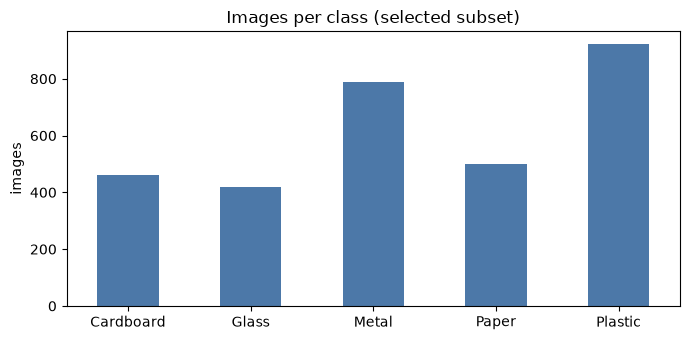

In [3]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}

def images_in(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

# find the folder of each class anywhere inside the extracted data
found = {}
for d in RAW_DIR.rglob('*'):
    if d.is_dir() and '__MACOSX' not in d.parts:
        for cls in CLASSES:
            if d.name.strip().lower() == cls.lower():
                n = len(images_in(d))
                if n and n > len(found.get(cls, [])): found[cls] = images_in(d)

missing = [c for c in CLASSES if c not in found]
assert not missing, f'Could not find image folders for: {missing}. Check the zip contents / class names.'

paths  = [str(p) for c in CLASSES for p in found[c]]
labels = [CLASSES.index(c) for c in CLASSES for _ in found[c]]
counts = pd.Series({c: len(found[c]) for c in CLASSES}, name='images')
print(counts.to_string()); print('TOTAL:', counts.sum())
assert counts.min() >= 100, 'Midterm requires at least 100 samples per class'

ax = counts.plot(kind='bar', color='#4c78a8', figsize=(7,3.5), title='Images per class (selected subset)')
ax.set_ylabel('images'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

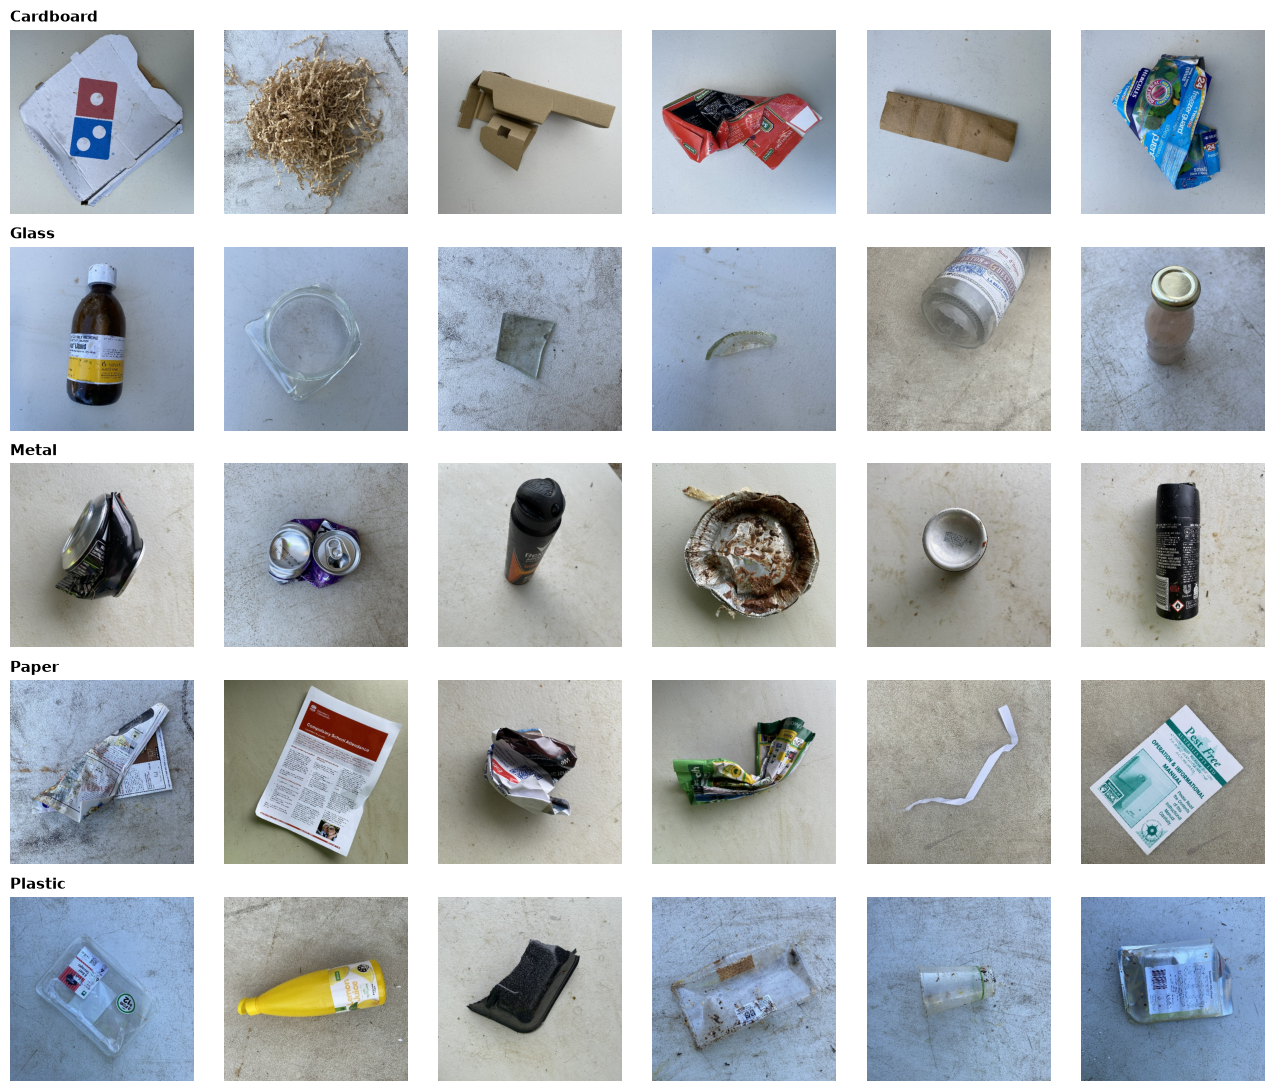

In [4]:
# sample images from each class
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(13, 2.2*len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(random.sample(found[c], 6)):
        axes[i, j].imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); axes[i, j].axis('off')
    axes[i, 0].set_title(c, loc='left', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

## Step 3. Training / Validation / Testing split
The split is **stratified** (each class keeps the same proportion in every set) and is done **before** augmentation, so no validation or test image is ever used for training.

In [ ]:
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=SPLIT[1]+SPLIT[2],
                                            stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=SPLIT[2]/(SPLIT[1]+SPLIT[2]),
                                          stratify=y_tmp, random_state=SEED)
# Sanity check: no file path should ever appear in more than one split.
assert not (set(p_tr)&set(p_va) or set(p_tr)&set(p_te) or set(p_va)&set(p_te)), 'Leak between sets!'

split_df = pd.DataFrame({
    'Training':   pd.Series(y_tr).map(dict(enumerate(CLASSES))).value_counts(),
    'Validation': pd.Series(y_va).map(dict(enumerate(CLASSES))).value_counts(),
    'Testing':    pd.Series(y_te).map(dict(enumerate(CLASSES))).value_counts()}).loc[CLASSES]
split_df['Total'] = split_df.sum(axis=1); split_df.loc['TOTAL'] = split_df.sum()
display(split_df)
pd.DataFrame({'path': p_tr+p_va+p_te, 'label': y_tr+y_va+y_te,
              'split': ['train']*len(p_tr)+['val']*len(p_va)+['test']*len(p_te)}).to_csv('split.csv', index=False)

In [5]:
# --- Local reproduction addition (not part of the original Colab run) ---
# Loads the group's actual recorded train/val/test split (dataset/split.csv) instead of
# recomputing train_test_split here, so this evaluation runs against the exact same test
# set the group's reported numbers are based on.
import pandas as _pd
_split_path = os.environ.get('SPLIT_CSV_PATH', '../dataset/split.csv')
_split_df_raw = _pd.read_csv(_split_path)
_split_df_raw['path'] = _split_df_raw['path'].str.replace('\\\\', '/', regex=True)

def _paths_labels(split_name):
    rows = _split_df_raw[_split_df_raw['split'] == split_name]
    return [str(RAW_DIR.parent / p) for p in rows['path']], list(rows['label'])

p_tr, y_tr = _paths_labels('train')
p_va, y_va = _paths_labels('val')
p_te, y_te = _paths_labels('test')

assert not (set(p_tr) & set(p_va) or set(p_tr) & set(p_te) or set(p_va) & set(p_te)), 'Leak between sets!'
for p in (p_tr[0], p_va[0], p_te[0]):
    assert os.path.exists(p), f'Missing file referenced by split.csv: {p}'

split_df = pd.DataFrame({
    'Training':   pd.Series(y_tr).map(dict(enumerate(CLASSES))).value_counts(),
    'Validation': pd.Series(y_va).map(dict(enumerate(CLASSES))).value_counts(),
    'Testing':    pd.Series(y_te).map(dict(enumerate(CLASSES))).value_counts()}).loc[CLASSES]
split_df['Total'] = split_df.sum(axis=1); split_df.loc['TOTAL'] = split_df.sum()
display(split_df)
print(f'Loaded split from {_split_path}: {len(p_tr)} train / {len(p_va)} val / {len(p_te)} test')


,Training,Validation,Testing,Total
Cardboard,323,69,69,461
Glass,294,63,63,420
Metal,553,118,119,790
Paper,350,75,75,500
Plastic,644,139,138,921
TOTAL,2164,464,464,3092


Loaded split from /home/jave/.treehouse/cv-object-sorting-7546a8/2/cv-object-sorting/dataset/split.csv: 2164 train / 464 val / 464 test


## Step 4. Preprocessing and augmentation
**Preprocessing (every image):** read → decode as 3-channel RGB → resize to 224×224 → scale pixel values to [-1, 1] (done inside the model so the demo uses exactly the same steps).
**Augmentation (training set only):** random flip, rotation, zoom, brightness and contrast, to prepare the model for unseen lighting and viewing angles.

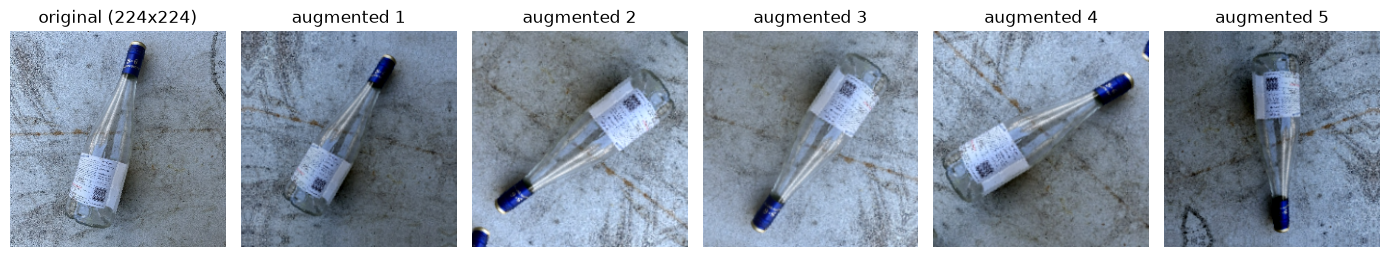

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # RGB
    img = tf.image.resize(img, IMG_SIZE, antialias=True)                 # 224x224
    img.set_shape((*IMG_SIZE, 3))
    return img, label                                                    # float32, 0-255

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, np.array(y, dtype=np.int32)))
    if shuffle: ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(p_tr, y_tr, shuffle=True)
val_ds   = make_ds(p_va, y_va)
test_ds  = make_ds(p_te, y_te)          # not shuffled, so predictions line up with y_te

augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name='augmentation')

# preview: one image, original vs. augmented versions
img0 = cv2.cvtColor(cv2.imread(p_tr[0]), cv2.COLOR_BGR2RGB)
x0 = tf.image.resize(img0, IMG_SIZE)[None].numpy().astype('float32')
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(x0[0].astype('uint8')); axes[0].set_title('original (224x224)')
for k in range(1, 6):
    axes[k].imshow(augment(x0, training=True)[0].numpy().clip(0,255).astype('uint8')); axes[k].set_title(f'augmented {k}')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

## Step 5. Model and training
**Model:** MobileNetV2 pre-trained on ImageNet (transfer learning) + global average pooling + dropout + a 5-way softmax layer.
**Stage 1:** train only the new top layers. **Stage 2:** fine-tune the upper part of MobileNetV2 at a low learning rate.
Class weights compensate for the imbalance between classes (e.g. Plastic vs Glass).

In [ ]:
def build_model(num_classes):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augment(inputs)                               # active only while training
    x = layers.Rescaling(1/127.5, offset=-1)(x)       # pixel values -> [-1, 1]
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights=WEIGHTS)
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return keras.Model(inputs, outputs), base

model, base = build_model(len(CLASSES))
cw = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=np.array(y_tr))
class_weight = dict(enumerate(cw)); print('class weights:', {CLASSES[k]: round(v,2) for k,v in class_weight.items()})

# Stop (and roll back to) the best validation-loss epoch if it stalls for 4 epochs in a
# row; halve the learning rate if it stalls for 2 epochs in a row.
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)]

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, class_weight=class_weight, callbacks=callbacks)
print(f'Stage 1 done in {(time.time()-t0)/60:.1f} min')

In [ ]:
# Stage 2: fine-tune the last layers of MobileNetV2 (BatchNorm layers stay frozen)
base.trainable = True
for layer in base.layers[:-40]:        # freeze everything except the last 40 layers
    layer.trainable = False
for layer in base.layers:              # BatchNorm stats stay frozen even in the unfrozen part
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
t0 = time.time()
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, class_weight=class_weight, callbacks=callbacks)
print(f'Stage 2 done in {(time.time()-t0)/60:.1f} min')

In [ ]:
# training curves (both stages joined)
acc  = hist1.history['accuracy']     + hist2.history['accuracy']
vacc = hist1.history['val_accuracy'] + hist2.history['val_accuracy']
loss = hist1.history['loss']         + hist2.history['loss']
vlos = hist1.history['val_loss']     + hist2.history['val_loss']
n1 = len(hist1.history['loss'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (t, v, name) in zip(ax, [(acc, vacc, 'Accuracy'), (loss, vlos, 'Loss')]):
    a.plot(t, label='training'); a.plot(v, label='validation')
    a.axvline(n1-0.5, color='gray', ls='--', label='fine-tuning starts'); a.set_title(name); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

Training logs omitted: this notebook's evaluation outputs were regenerated from the group's final trained model (results.json, 87.93%).

In [7]:
# --- Local reproduction addition (not part of the original Colab run) ---
# Loads the group's already-trained, saved model so Step 6 below can be re-evaluated
# without retraining. If the file isn't present (e.g. a fresh Colab run), this cell does
# nothing and the `model` trained in Step 5 above is used as-is.
from pathlib import Path as _Path
_saved_model_path = _Path(os.environ.get('SAVED_MODEL_PATH', '../models/waste_classifier.keras'))
if _saved_model_path.exists():
    model = keras.models.load_model(_saved_model_path)
    print(f'Loaded saved model from {_saved_model_path} (skipping retraining for this evaluation run).')
else:
    print('No saved model found at', _saved_model_path, '- using the model trained above.')


Loaded saved model from /home/jave/.treehouse/cv-object-sorting-7546a8/2/cv-object-sorting/models/waste_classifier.keras (skipping retraining for this evaluation run).


## Step 6. Evaluation on the Testing set
The test images were never used for training or for choosing when to stop training.

In [8]:
probs  = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(1); y_true = np.array(y_te)
test_acc = accuracy_score(y_true, y_pred)
print(f'TEST ACCURACY: {test_acc*100:.2f}%   ({(y_true==y_pred).sum()} of {len(y_true)} images correct)\n')

rep = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, digits=4, zero_division=0)
rep_df = pd.DataFrame(rep).T.round(4)
rep_df.loc['accuracy', ['precision','recall']] = np.nan; rep_df.loc['accuracy','f1-score'] = round(test_acc, 4); rep_df.loc['accuracy','support'] = len(y_true)
rep_df['support'] = rep_df['support'].astype(int)
display(rep_df)
print('Macro F1:', round(rep['macro avg']['f1-score'], 4), '| Weighted F1:', round(rep['weighted avg']['f1-score'], 4))

TEST ACCURACY: 87.93%   (408 of 464 images correct)



,precision,recall,f1-score,support
Cardboard,0.8806,0.8551,0.8676,69
Glass,0.8485,0.8889,0.8682,63
Metal,0.9052,0.8824,0.8936,119
Paper,0.8353,0.9467,0.8875,75
Plastic,0.9000,0.8478,0.8731,138
accuracy,NaN,NaN,0.8793,464
macro avg,0.8739,0.8842,0.8780,464
weighted avg,0.8810,0.8793,0.8792,464


Macro F1: 0.878 | Weighted F1: 0.8792


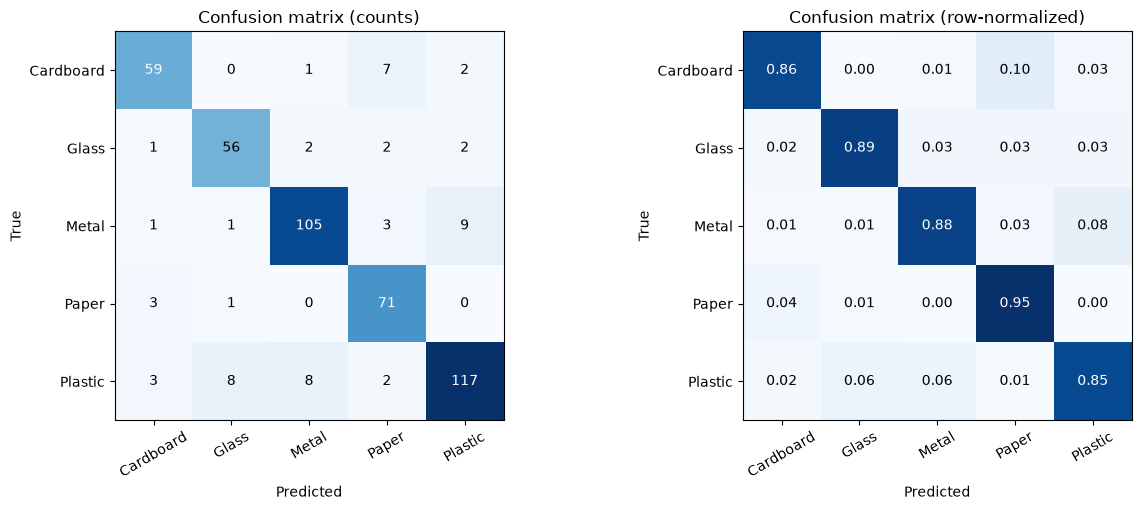

Most common mistakes (true -> predicted : count):
  Metal -> Plastic : 9
  Plastic -> Glass : 8
  Plastic -> Metal : 8
  Cardboard -> Paper : 7
  Metal -> Paper : 3


In [9]:
cm  = confusion_matrix(y_true, y_pred)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, M, title, fmt in [(axes[0], cm, 'Confusion matrix (counts)', 'd'), (axes[1], cmn, 'Confusion matrix (row-normalized)', '.2f')]:
    im = ax.imshow(M, cmap='Blues'); ax.set_title(title)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=30); ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, format(M[i, j], fmt), ha='center', va='center', color='white' if M[i, j] > M.max()/2 else 'black')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

# most confused pairs
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0]
print('Most common mistakes (true -> predicted : count):')
for t, p, n in sorted(pairs, key=lambda x: -x[2])[:5]: print(f'  {t} -> {p} : {n}')

56 misclassified test images; showing up to 10


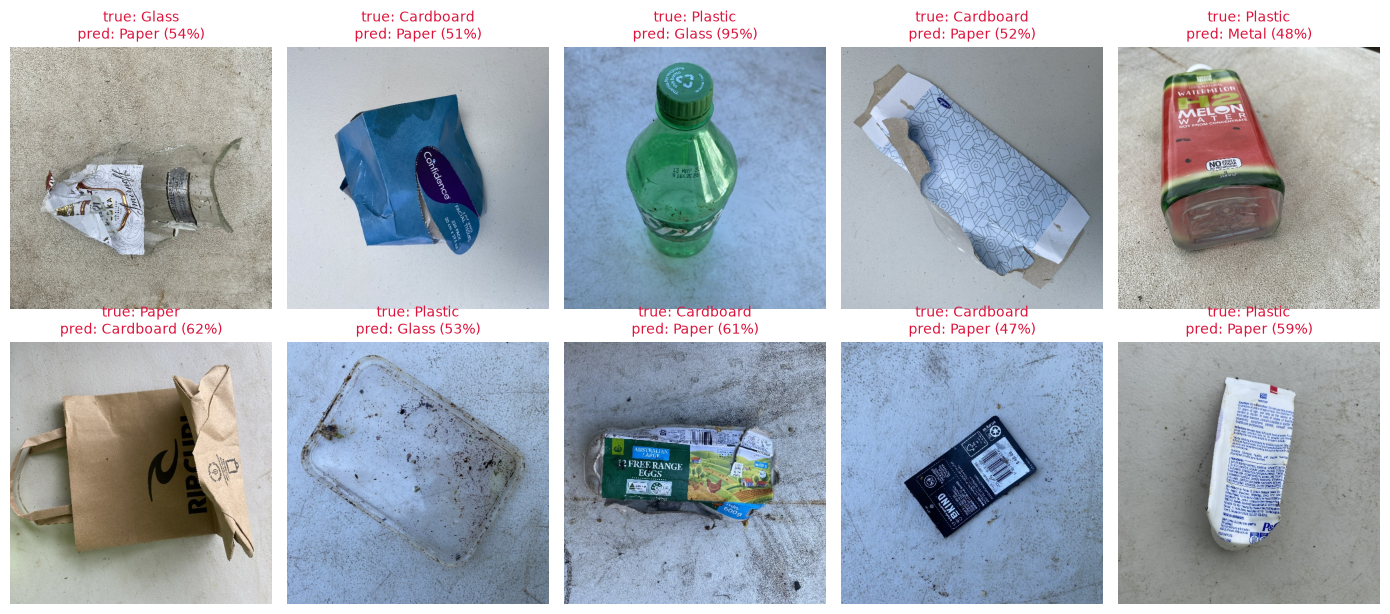

In [10]:
# examples the model got wrong
wrong = np.where(y_pred != y_true)[0]
print(f'{len(wrong)} misclassified test images; showing up to 10')
sel = wrong[:10]
if len(sel):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.2))
    for a in axes.ravel(): a.axis('off')
    for a, k in zip(axes.ravel(), sel):
        a.imshow(cv2.cvtColor(cv2.imread(p_te[k]), cv2.COLOR_BGR2RGB))
        a.set_title(f'true: {CLASSES[y_true[k]]}\npred: {CLASSES[y_pred[k]]} ({probs[k].max()*100:.0f}%)', fontsize=10, color='crimson')
    plt.tight_layout(); plt.show()

## Step 6b. ROC curves
One-vs-rest ROC curve per class on the test set, with per-class AUC and the macro-average AUC. AUC summarizes how well the model's confidence ranks true positives above false positives for each class, independent of the 0.60 cutoff.

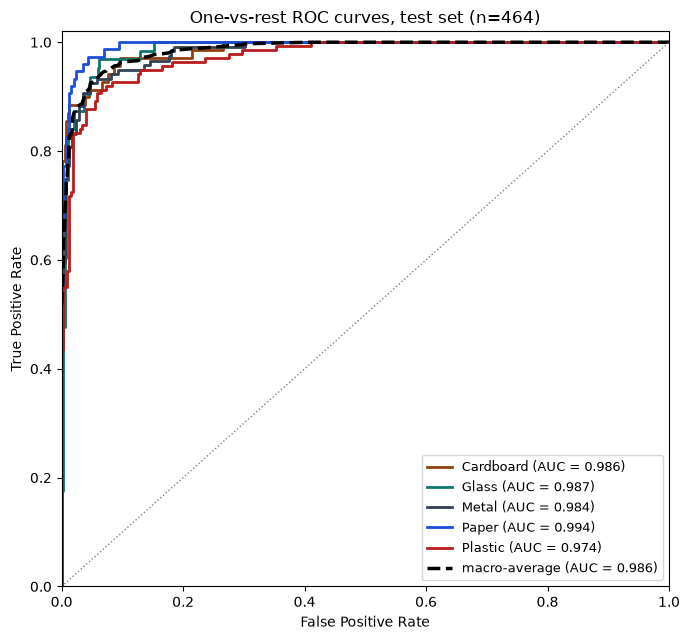

{
  "per_class_auc": {
    "Cardboard": 0.9863,
    "Glass": 0.9867,
    "Metal": 0.9835,
    "Paper": 0.9942,
    "Plastic": 0.974
  },
  "macro_auc": 0.9856,
  "n_test": 464
}


In [11]:
from sklearn.metrics import roc_curve, auc as _auc
import os as _os
from pathlib import Path as _Path

_results_dir = _Path(_os.environ.get('REPO_RESULTS_DIR', '../results')); _results_dir.mkdir(parents=True, exist_ok=True)

n_classes = len(CLASSES)
y_te_bin = np.eye(n_classes)[y_true]

fpr, tpr, roc_auc = {}, {}, {}
for i, c in enumerate(CLASSES):
    fpr[c], tpr[c], _ = roc_curve(y_te_bin[:, i], probs[:, i])
    roc_auc[c] = _auc(fpr[c], tpr[c])

_all_fpr = np.unique(np.concatenate([fpr[c] for c in CLASSES]))
_mean_tpr = np.zeros_like(_all_fpr)
for c in CLASSES:
    _mean_tpr += np.interp(_all_fpr, fpr[c], tpr[c])
_mean_tpr /= n_classes
macro_auc = _auc(_all_fpr, _mean_tpr)

fig, ax = plt.subplots(figsize=(7, 6.5))
_colors = ['#92400e', '#0f766e', '#334155', '#1d4ed8', '#b91c1c']
for c, color in zip(CLASSES, _colors):
    ax.plot(fpr[c], tpr[c], color=color, lw=2, label=f'{c} (AUC = {roc_auc[c]:.3f})')
ax.plot(_all_fpr, _mean_tpr, color='black', lw=2.5, ls='--', label=f'macro-average (AUC = {macro_auc:.3f})')
ax.plot([0, 1], [0, 1], color='gray', lw=1, ls=':')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title(f'One-vs-rest ROC curves, test set (n={len(y_true)})')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(_results_dir / 'roc_curves.png', dpi=150); plt.show()

roc_auc_out = {'per_class_auc': {c: round(float(roc_auc[c]), 4) for c in CLASSES},
               'macro_auc': round(float(macro_auc), 4), 'n_test': int(len(y_true))}
json.dump(roc_auc_out, open(_results_dir / 'roc_auc.json', 'w'), indent=2)
print(json.dumps(roc_auc_out, indent=2))


## Step 6c. Misclassified samples (figure for the report)
A captioned grid of test images the model got wrong, each labeled with the true class, the predicted class, and the model's confidence in that wrong prediction.

56 misclassified test images; sampling up to 10 for the figure


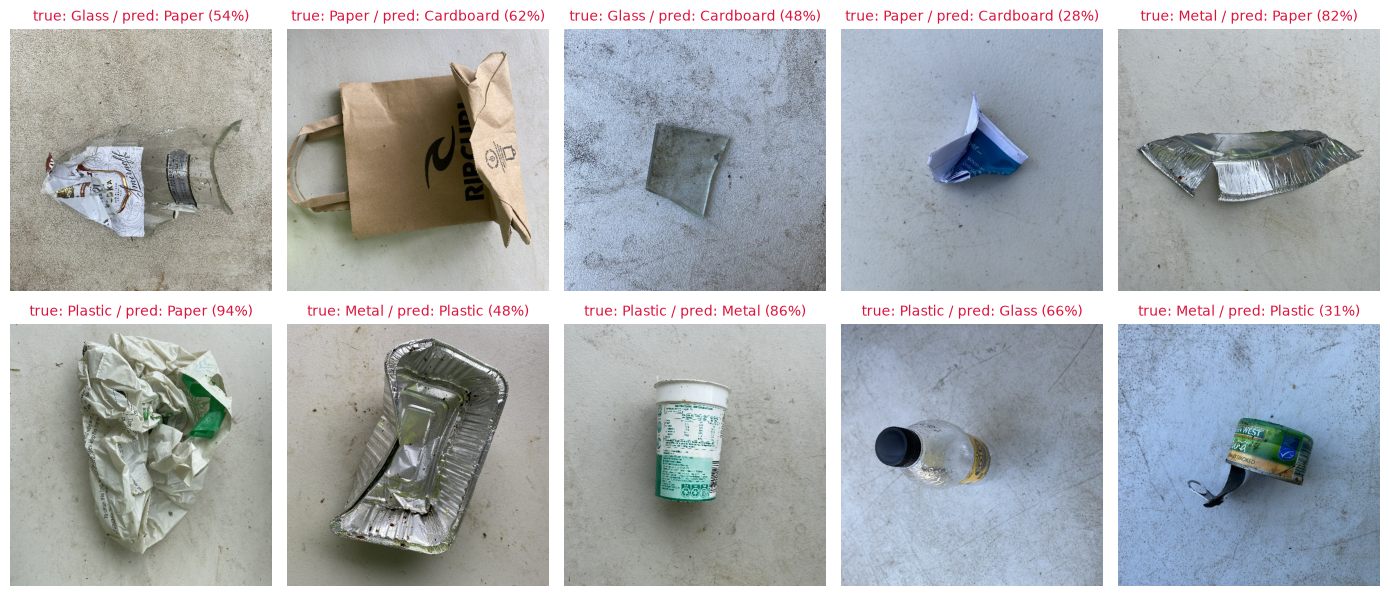

In [12]:
_wrong_idx = np.where(y_pred != y_true)[0]
print(f'{len(_wrong_idx)} misclassified test images; sampling up to 10 for the figure')
_rng = np.random.RandomState(42)
_sel = _rng.choice(_wrong_idx, size=min(10, len(_wrong_idx)), replace=False)
_sel.sort()

_n_cols = 5
_n_rows = int(np.ceil(len(_sel) / _n_cols))
fig, axes = plt.subplots(_n_rows, _n_cols, figsize=(14, 3.1 * _n_rows))
axes = np.array(axes).reshape(-1)
for a in axes: a.axis('off')
for a, k in zip(axes, _sel):
    img = cv2.cvtColor(cv2.imread(p_te[k]), cv2.COLOR_BGR2RGB)
    a.imshow(img)
    a.set_title(f'true: {CLASSES[y_true[k]]} / pred: {CLASSES[y_pred[k]]} ({probs[k].max()*100:.0f}%)',
                fontsize=10, color='crimson')
plt.tight_layout()
plt.savefig(_results_dir / 'misclassified_samples.png', dpi=150); plt.show()


## Step 6d. Threshold justification data
On the **validation** set, for a range of confidence thresholds: coverage (the share of images the model is confident enough to label), accuracy among the covered images, and the share of the model's wrong predictions that fall below the threshold (and so get shown as "Uncertain" instead of a wrong label). The same row is also computed once on the held-out **test** set at t=0.60, the previously hand-picked value, for comparison with the data-driven choice in Step 6f.

Predicting on the validation set (used by Steps 6d-6g)...


{
  "validation_sweep": [
    {
      "threshold": 0.4,
      "coverage": 0.9828,
      "accuracy_on_covered": 0.864,
      "pct_wrong_caught_as_uncertain": 0.1014,
      "n_images": 464
    },
    {
      "threshold": 0.5,
      "coverage": 0.9461,
      "accuracy_on_covered": 0.877,
      "pct_wrong_caught_as_uncertain": 0.2174,
      "n_images": 464
    },
    {
      "threshold": 0.6,
      "coverage": 0.8836,
      "accuracy_on_covered": 0.9098,
      "pct_wrong_caught_as_uncertain": 0.4638,
      "n_images": 464
    },
    {
      "threshold": 0.7,
      "coverage": 0.8103,
      "accuracy_on_covered": 0.9362,
      "pct_wrong_caught_as_uncertain": 0.6522,
      "n_images": 464
    },
    {
      "threshold": 0.8,
      "coverage": 0.7349,
      "accuracy_on_covered": 0.9589,
      "pct_wrong_caught_as_uncertain": 0.7971,
      "n_images": 464
    },
    {
      "threshold": 0.9,
      "coverage": 0.5948,
      "accuracy_on_covered": 0.9855,
      "pct_wrong_caught_as_uncertain":

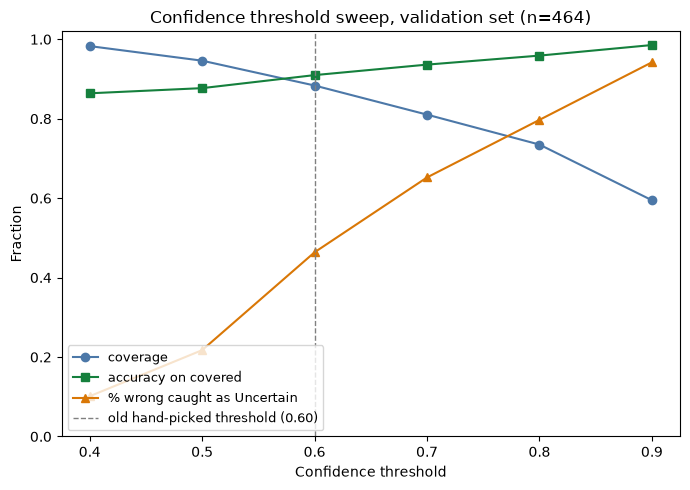

In [13]:
print('Predicting on the validation set (used by Steps 6d-6g)...')
probs_va = model.predict(val_ds, verbose=0)
y_va_arr = np.array(y_va)
p_max_va = probs_va.max(1)
y_pred_va = probs_va.argmax(1)
correct_va = (y_pred_va == y_va_arr)

def sweep_row(probs_, y_true_, t):
    p_max_ = probs_.max(1); y_pred_ = probs_.argmax(1)
    covered = p_max_ >= t
    coverage = float(covered.mean())
    acc_covered = float((y_pred_[covered] == y_true_[covered]).mean()) if covered.sum() else None
    wrong = y_pred_ != y_true_
    n_wrong = int(wrong.sum())
    caught = int((wrong & ~covered).sum())
    pct_caught = float(caught / n_wrong) if n_wrong else None
    return {'threshold': t, 'coverage': round(coverage, 4),
            'accuracy_on_covered': round(acc_covered, 4) if acc_covered is not None else None,
            'pct_wrong_caught_as_uncertain': round(pct_caught, 4) if pct_caught is not None else None,
            'n_images': int(len(y_true_))}

_sweep_thresholds = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
sweep_val = [sweep_row(probs_va, y_va_arr, t) for t in _sweep_thresholds]
sweep_test_060 = sweep_row(probs, y_true, CONF_THRESH)
threshold_sweep_out = {'validation_sweep': sweep_val, 'test_at_0.60': sweep_test_060}
json.dump(threshold_sweep_out, open(_results_dir / 'threshold_sweep.json', 'w'), indent=2)
print(json.dumps(threshold_sweep_out, indent=2))

fig, ax1 = plt.subplots(figsize=(7, 5))
_ts = [r['threshold'] for r in sweep_val]
ax1.plot(_ts, [r['coverage'] for r in sweep_val], 'o-', color='#4c78a8', label='coverage')
ax1.plot(_ts, [r['accuracy_on_covered'] for r in sweep_val], 's-', color='#15803d', label='accuracy on covered')
ax1.plot(_ts, [r['pct_wrong_caught_as_uncertain'] for r in sweep_val], '^-', color='#d97706', label='% wrong caught as Uncertain')
ax1.axvline(CONF_THRESH, color='gray', ls='--', lw=1, label='old hand-picked threshold (0.60)')
ax1.set_xlabel('Confidence threshold'); ax1.set_ylabel('Fraction'); ax1.set_ylim(0, 1.02)
ax1.set_title(f'Confidence threshold sweep, validation set (n={len(y_va_arr)})')
ax1.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.savefig(_results_dir / 'threshold_sweep.png', dpi=150); plt.show()


## Step 6e. Confidence calibration
A reliability diagram bins test predictions by confidence and compares mean confidence to actual accuracy in each bin; a perfectly calibrated model would sit on the diagonal. We report the Expected and Maximum Calibration Error (ECE, MCE), then fit a single temperature `T` on the **validation** set only (never on test) and re-check test ECE after scaling. Temperature scaling only rescales confidence - it cannot and does not change which class the model predicts, so it leaves the 87.93% test accuracy untouched. This is an analysis for the report only: the deployed demo keeps using raw softmax confidence, unscaled.

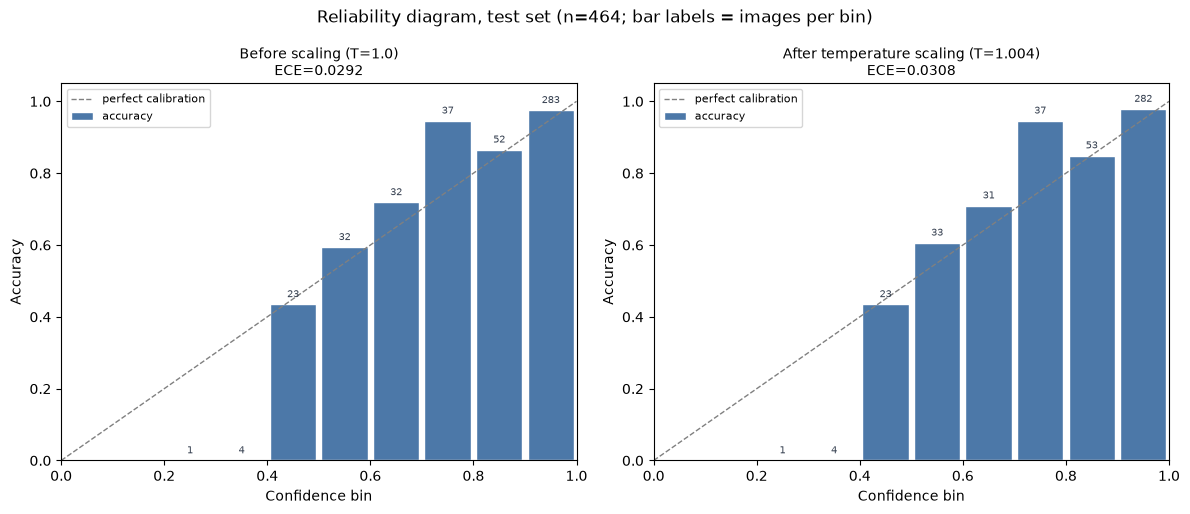

{
  "test_ece_before_scaling": 0.0292,
  "test_mce_before_scaling": 0.3441,
  "temperature_T_fit_on_validation": 1.0038,
  "test_ece_after_scaling": 0.0308,
  "test_mce_after_scaling": 0.3436,
  "note": "Temperature scaling is an analysis only; it does not change the predicted class or the 87.93% test accuracy, and is not used by the deployed demo (which reports raw softmax confidence).",
  "accuracy_on_test_predictions_ge_0.60": 0.9381,
  "n_test_predictions_ge_0.60": 404,
  "per_class_ece_test": {
    "Cardboard": 0.0151,
    "Glass": 0.0307,
    "Metal": 0.0232,
    "Paper": 0.0239,
    "Plastic": 0.0308
  }
}


In [14]:
from scipy.optimize import minimize_scalar

def reliability_bins(probs_, y_true_, n_bins=10):
    p_max_ = probs_.max(1); y_pred_ = probs_.argmax(1)
    correct_ = (y_pred_ == y_true_).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(p_max_, edges[1:-1], right=True), 0, n_bins - 1)
    bins_, ece_, mce_, n_ = [], 0.0, 0.0, len(p_max_)
    for b in range(n_bins):
        m = idx == b; cnt = int(m.sum())
        if cnt == 0:
            bins_.append({'bin_lo': round(float(edges[b]),2), 'bin_hi': round(float(edges[b+1]),2), 'count': 0,
                          'mean_confidence': None, 'accuracy': None})
            continue
        mc = float(p_max_[m].mean()); ac = float(correct_[m].mean()); gap = abs(mc - ac)
        ece_ += (cnt/n_) * gap; mce_ = max(mce_, gap)
        bins_.append({'bin_lo': round(float(edges[b]),2), 'bin_hi': round(float(edges[b+1]),2), 'count': cnt,
                      'mean_confidence': round(mc,4), 'accuracy': round(ac,4)})
    return bins_, round(float(ece_),4), round(float(mce_),4)

bins_before, ece_before, mce_before = reliability_bins(probs, y_true)

# Pre-softmax logits: the final Dense layer bakes activation='softmax' into its call(),
# so its pre-activation isn't a separate graph output. Reconstruct it by running the
# model up to the layer just before Dense (Dropout is identity at inference) and
# applying the Dense layer's own weights by hand.
_feat_model = keras.Model(model.input, model.get_layer('dropout').output)
_W, _b = model.get_layer('dense').get_weights()

def get_logits(ds):
    return _feat_model.predict(ds, verbose=0) @ _W + _b

logits_va = get_logits(val_ds)
logits_te = get_logits(test_ds)
assert np.allclose(tf.nn.softmax(logits_te, axis=1).numpy(), probs, atol=1e-4), 'logit reconstruction mismatch'

def fit_temperature(logits_, y_true_):
    y_true_t = tf.constant(y_true_, dtype=tf.int32)
    logits_t = tf.constant(logits_, dtype=tf.float32)
    def nll(log_t):
        T_ = tf.exp(tf.cast(log_t[0], tf.float32))
        logp = tf.nn.log_softmax(logits_t / T_, axis=1)
        return -tf.reduce_mean(tf.gather(logp, y_true_t, axis=1, batch_dims=1))
    res = minimize_scalar(lambda lt: float(nll(np.array([lt]))), bounds=(-3.0, 3.0), method='bounded')
    return float(np.exp(res.x))

T = fit_temperature(logits_va, y_va_arr)
probs_scaled = tf.nn.softmax(logits_te / T, axis=1).numpy()
assert np.array_equal(probs_scaled.argmax(1), probs.argmax(1)), 'temperature scaling changed predictions!'
bins_after, ece_after, mce_after = reliability_bins(probs_scaled, y_true)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, bins_, title, in [(axes[0], bins_before, f'Before scaling (T=1.0)\nECE={ece_before:.4f}'),
                           (axes[1], bins_after, f'After temperature scaling (T={T:.3f})\nECE={ece_after:.4f}')]:
    centers = [(b['bin_lo']+b['bin_hi'])/2 for b in bins_]
    accs = [b['accuracy'] if b['accuracy'] is not None else 0 for b in bins_]
    _bin_counts = [b['count'] for b in bins_]
    ax.bar(centers, accs, width=0.09, color='#4c78a8', edgecolor='white', label='accuracy')
    ax.plot([0,1],[0,1], color='gray', ls='--', lw=1, label='perfect calibration')
    for c, a, n in zip(centers, accs, _bin_counts):
        if n > 0: ax.text(c, a+0.02, str(n), ha='center', fontsize=7, color='#374151')
    ax.set_xlim(0,1); ax.set_ylim(0,1.05); ax.set_xlabel('Confidence bin'); ax.set_ylabel('Accuracy')
    ax.set_title(title, fontsize=10); ax.legend(loc='upper left', fontsize=8)
plt.suptitle(f'Reliability diagram, test set (n={len(y_true)}; bar labels = images per bin)')
plt.tight_layout()
plt.savefig(_results_dir / 'reliability_diagram.png', dpi=150); plt.show()

_near = probs.max(1) >= 0.60
_acc_near = float((y_pred[_near] == y_true[_near]).mean()) if _near.sum() else None

def per_class_ece(probs_, y_true_, n_bins=10):
    out_ = {}
    for ci, c in enumerate(CLASSES):
        conf = probs_[:, ci]; is_c = (y_true_ == ci).astype(float)
        edges = np.linspace(0.0, 1.0, n_bins + 1)
        idx = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)
        ece_, n_, bins_ = 0.0, len(conf), []
        for b in range(n_bins):
            m = idx == b; cnt = int(m.sum())
            if cnt == 0:
                bins_.append({'bin_lo': round(float(edges[b]),2), 'bin_hi': round(float(edges[b+1]),2), 'count': 0}); continue
            mc = float(conf[m].mean()); fr = float(is_c[m].mean())
            ece_ += (cnt/n_) * abs(mc - fr)
            bins_.append({'bin_lo': round(float(edges[b]),2), 'bin_hi': round(float(edges[b+1]),2), 'count': cnt,
                          'mean_confidence': round(mc,4), 'empirical_frequency': round(fr,4)})
        out_[c] = {'ece': round(float(ece_),4), 'bins': bins_}
    return out_

per_class_ece_out = per_class_ece(probs, y_true)

calibration_out = {
    'test_reliability_bins': bins_before, 'test_ece_before_scaling': ece_before, 'test_mce_before_scaling': mce_before,
    'temperature_T_fit_on_validation': round(T, 4),
    'test_reliability_bins_after_scaling': bins_after, 'test_ece_after_scaling': ece_after, 'test_mce_after_scaling': mce_after,
    'note': 'Temperature scaling is an analysis only; it does not change the predicted class or the 87.93% test accuracy, and is not used by the deployed demo (which reports raw softmax confidence).',
    'accuracy_on_test_predictions_ge_0.60': round(_acc_near, 4) if _acc_near is not None else None,
    'n_test_predictions_ge_0.60': int(_near.sum()),
    'per_class_ece_test': {c: per_class_ece_out[c]['ece'] for c in CLASSES},
    'per_class_reliability_bins_test': {c: per_class_ece_out[c]['bins'] for c in CLASSES},
}
json.dump(calibration_out, open(_results_dir / 'calibration.json', 'w'), indent=2)
print(json.dumps({k: v for k, v in calibration_out.items() if 'bins' not in k}, indent=2))


## Step 6f. Choosing the confidence threshold from data
Instead of a hand-picked 0.60, sweep the threshold on the **validation** set (using the same raw softmax confidence the deployed demo shows) and pick the smallest threshold whose validation selective accuracy reaches the report's 90% target - the smallest threshold keeps the most images labeled while still meeting the target. The chosen value is then checked once, and only once, on the test set.

{
  "selection_rule": "smallest t with validation selective accuracy >= 90%",
  "target_accuracy": 0.9,
  "chosen_threshold": 0.59,
  "validation_row_at_chosen_t": {
    "t": 0.59,
    "coverage": 0.8901,
    "selective_accuracy": 0.9031
  },
  "test_row_at_chosen_t": {
    "threshold": 0.59,
    "coverage": 0.8772,
    "accuracy_on_covered": 0.9337,
    "pct_wrong_caught_as_uncertain": 0.5179,
    "n_images": 464,
    "n_errors_caught": 29,
    "n_errors_total": 56
  }
}


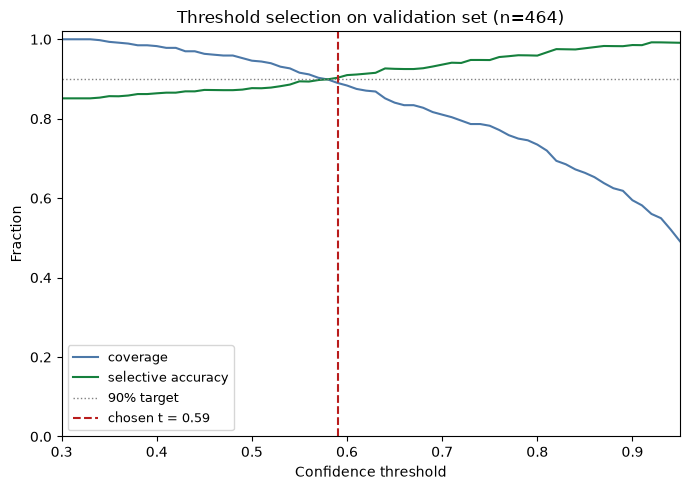

CHOSEN GLOBAL THRESHOLD: 0.59


In [15]:
TARGET_ACC = 0.90
MIN_COVERAGE = 0.50
_fine_ts = np.round(np.arange(0.30, 0.95 + 1e-9, 0.01), 2)

fine_sweep = []
for t in _fine_ts:
    covered = p_max_va >= t
    coverage = float(covered.mean())
    sel_acc = float(correct_va[covered].mean()) if covered.sum() else None
    fine_sweep.append({'t': float(t), 'coverage': round(coverage,4),
                        'selective_accuracy': round(sel_acc,4) if sel_acc is not None else None})

_candidates = [r for r in fine_sweep if r['selective_accuracy'] is not None and r['selective_accuracy'] >= TARGET_ACC]
if _candidates:
    chosen = min(_candidates, key=lambda r: r['t'])
    selection_method = f'smallest t with validation selective accuracy >= {TARGET_ACC:.0%}'
else:
    best_f1, chosen = -1.0, None
    for t in _fine_ts:
        covered = p_max_va >= t
        wrong = ~correct_va
        tp = int((wrong & ~covered).sum()); fn = int((wrong & covered).sum()); fp = int((correct_va & ~covered).sum())
        precision = tp/(tp+fp) if (tp+fp) else 0.0
        recall = tp/(tp+fn) if (tp+fn) else 0.0
        f1 = 2*precision*recall/(precision+recall) if (precision+recall) else 0.0
        if f1 > best_f1:
            best_f1 = f1
            chosen = {'t': float(t), 'coverage': round(float((p_max_va>=t).mean()),4),
                      'selective_accuracy': round(float(correct_va[p_max_va>=t].mean()),4) if (p_max_va>=t).sum() else None,
                      'error_catch_f1': round(f1,4)}
    selection_method = (f'no t reached {TARGET_ACC:.0%} validation selective accuracy with coverage >= '
                        f'{MIN_COVERAGE:.0%}; picked the t maximizing the F1 of catching wrong predictions as Uncertain instead')

CHOSEN_T = round(chosen['t'], 2)
test_row = sweep_row(probs, y_true, CHOSEN_T)
_wrong_te = y_pred != y_true; _covered_te = probs.max(1) >= CHOSEN_T
test_row['n_errors_caught'] = int((_wrong_te & ~_covered_te).sum())
test_row['n_errors_total'] = int(_wrong_te.sum())

threshold_selection_out = {'selection_rule': selection_method, 'target_accuracy': TARGET_ACC,
                            'chosen_threshold': CHOSEN_T, 'validation_row_at_chosen_t': chosen,
                            'test_row_at_chosen_t': test_row, 'validation_sweep_fine': fine_sweep}
json.dump(threshold_selection_out, open(_results_dir / 'threshold_selection.json', 'w'), indent=2)
print(json.dumps({k: v for k, v in threshold_selection_out.items() if k != 'validation_sweep_fine'}, indent=2))

fig, ax = plt.subplots(figsize=(7, 5))
_tsp = [r['t'] for r in fine_sweep]
ax.plot(_tsp, [r['coverage'] for r in fine_sweep], color='#4c78a8', lw=1.5, label='coverage')
ax.plot(_tsp, [r['selective_accuracy'] if r['selective_accuracy'] is not None else np.nan for r in fine_sweep],
        color='#15803d', lw=1.5, label='selective accuracy')
ax.axhline(TARGET_ACC, color='gray', ls=':', lw=1, label=f'{TARGET_ACC:.0%} target')
ax.axvline(CHOSEN_T, color='#b91c1c', ls='--', lw=1.5, label=f'chosen t = {CHOSEN_T:.2f}')
ax.set_xlim(0.30, 0.95); ax.set_ylim(0, 1.02)
ax.set_xlabel('Confidence threshold'); ax.set_ylabel('Fraction')
ax.set_title(f'Threshold selection on validation set (n={len(y_va_arr)})')
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.savefig(_results_dir / 'threshold_selection.png', dpi=150); plt.show()
print(f'CHOSEN GLOBAL THRESHOLD: {CHOSEN_T}')


## Step 6g. Per-class confidence thresholds
The classes are not equally confident or equally precise, so a single global threshold is a compromise. For each **predicted** class, sweep the threshold on validation and pick the smallest value where precision among kept predictions (true label matches, confidence above the threshold) reaches 90%. Validation counts per class are small (about 60-140), so a class falls back to the global threshold (Step 6f) if fewer than 20 predictions remain at any threshold, or 90% precision is never reached - this is recorded, not hidden. The resulting thresholds are evaluated once on test and written to `models/class_thresholds.json`, which the live demo loads.

Per-class thresholds (validation):
{
  "Cardboard": {
    "t_c": 0.64,
    "is_fallback": false,
    "fallback_reason": null,
    "n_validation_predictions_of_class": 73
  },
  "Glass": {
    "t_c": 0.58,
    "is_fallback": false,
    "fallback_reason": null,
    "n_validation_predictions_of_class": 59
  },
  "Metal": {
    "t_c": 0.52,
    "is_fallback": false,
    "fallback_reason": null,
    "n_validation_predictions_of_class": 118
  },
  "Paper": {
    "t_c": 0.55,
    "is_fallback": false,
    "fallback_reason": null,
    "n_validation_predictions_of_class": 78
  },
  "Plastic": {
    "t_c": 0.6,
    "is_fallback": false,
    "fallback_reason": null,
    "n_validation_predictions_of_class": 136
  }
}
{
  "method": "for each predicted class, smallest t with validation precision-on-kept >= 90% and at least 20 kept predictions; else fall back to the global threshold (Step 6f rule)",
  "global_threshold_for_comparison": 0.59,
  "old_threshold_for_comparison": 0.6,
  "per_class_thresho

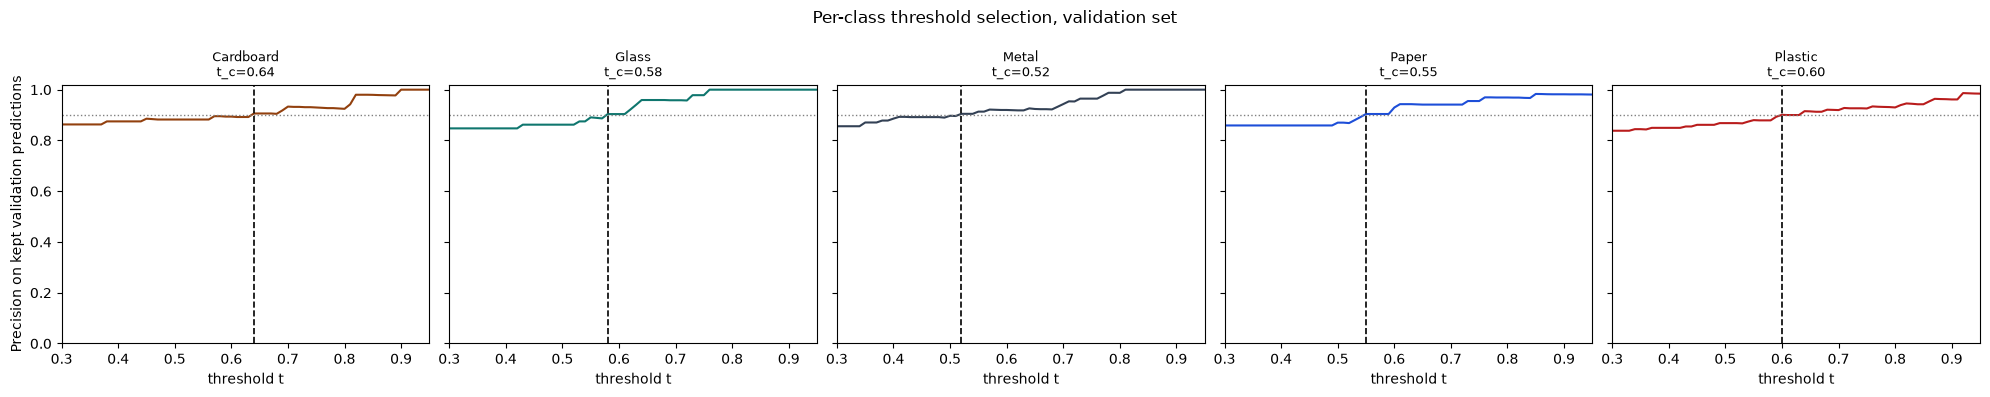

In [16]:
MIN_KEPT = 20
_class_fine_ts = np.round(np.arange(0.30, 0.95 + 1e-9, 0.01), 2)
class_thresholds = {}
class_curves = {}
for ci, c in enumerate(CLASSES):
    pred_c_va = y_pred_va == ci
    n_pred_c = int(pred_c_va.sum())
    curve, chosen_tc, fallback_reason = [], None, None
    for t in _class_fine_ts:
        kept = pred_c_va & (p_max_va >= t)
        n_kept = int(kept.sum())
        if n_kept == 0:
            curve.append({'t': float(t), 'n_kept': 0, 'precision': None}); continue
        precision = float((y_va_arr[kept] == ci).mean())
        curve.append({'t': float(t), 'n_kept': n_kept, 'precision': round(precision, 4)})
        if chosen_tc is None and n_kept >= MIN_KEPT and precision >= TARGET_ACC:
            chosen_tc = float(t)
    class_curves[c] = curve
    if chosen_tc is None:
        chosen_tc = CHOSEN_T
        if n_pred_c == 0:
            fallback_reason = f'no validation images predicted as {c}; using the global threshold'
        elif not any(r['n_kept'] >= MIN_KEPT for r in curve):
            fallback_reason = f'fewer than {MIN_KEPT} validation predictions of {c} remain at any threshold tried; using the global threshold'
        else:
            fallback_reason = f'validation precision for {c} never reached {TARGET_ACC:.0%} while keeping >= {MIN_KEPT} predictions; using the global threshold'
    class_thresholds[c] = {'t_c': round(chosen_tc, 2), 'is_fallback': fallback_reason is not None,
                           'fallback_reason': fallback_reason, 'n_validation_predictions_of_class': n_pred_c}
print('Per-class thresholds (validation):'); print(json.dumps(class_thresholds, indent=2))

def eval_policy(probs_, y_true_, get_threshold):
    y_pred_ = probs_.argmax(1); p_max_ = probs_.max(1)
    per_t = np.array([get_threshold(c) for c in y_pred_])
    kept = p_max_ >= per_t
    coverage = float(kept.mean())
    sel_acc = float((y_pred_[kept] == y_true_[kept]).mean()) if kept.sum() else None
    wrong = y_pred_ != y_true_
    per_class = {}
    for ci, c in enumerate(CLASSES):
        pred_c = y_pred_ == ci; kept_c = pred_c & kept
        per_class[c] = {'n_predicted': int(pred_c.sum()), 'n_kept': int(kept_c.sum()),
                        'coverage': round(float(kept_c.sum()/pred_c.sum()),4) if pred_c.sum() else None,
                        'precision_on_kept': round(float((y_true_[kept_c]==ci).mean()),4) if kept_c.sum() else None}
    return {'overall_coverage': round(coverage,4), 'overall_selective_accuracy': round(sel_acc,4) if sel_acc is not None else None,
            'errors_caught': int((wrong & ~kept).sum()), 'errors_total': int(wrong.sum()), 'per_class': per_class}

_t_c_array = {ci: class_thresholds[c]['t_c'] for ci, c in enumerate(CLASSES)}
test_per_class_policy = eval_policy(probs, y_true, lambda ci: _t_c_array[ci])
test_global_policy = eval_policy(probs, y_true, lambda ci: CHOSEN_T)
test_old_060_policy = eval_policy(probs, y_true, lambda ci: 0.60)

class_thresholds_out = {
    'method': f'for each predicted class, smallest t with validation precision-on-kept >= {TARGET_ACC:.0%} and at least {MIN_KEPT} kept predictions; else fall back to the global threshold (Step 6f rule)',
    'global_threshold_for_comparison': CHOSEN_T, 'old_threshold_for_comparison': 0.60,
    'per_class_thresholds': class_thresholds,
    'test_evaluation': {'per_class_thresholds_policy': test_per_class_policy,
                        'global_threshold_policy': test_global_policy, 'old_0.60_policy': test_old_060_policy},
}
json.dump(class_thresholds_out, open(_results_dir / 'class_thresholds.json', 'w'), indent=2)
print(json.dumps(class_thresholds_out, indent=2))

_models_dir = _Path(_os.environ.get('MODELS_DIR', '../models'))
json.dump({c: class_thresholds[c]['t_c'] for c in CLASSES}, open(_models_dir / 'class_thresholds.json', 'w'), indent=2)
print('Wrote', _models_dir / 'class_thresholds.json')

fig, axes = plt.subplots(1, n_classes, figsize=(4*n_classes, 4), sharey=True)
for ax, c, color in zip(axes, CLASSES, _colors):
    curve = class_curves[c]
    _tc = [r['t'] for r in curve]; _pc = [r['precision'] if r['precision'] is not None else np.nan for r in curve]
    ax.plot(_tc, _pc, color=color, lw=1.5)
    ax.axhline(TARGET_ACC, color='gray', ls=':', lw=1)
    ax.axvline(class_thresholds[c]['t_c'], color='black', ls='--', lw=1.2)
    ax.set_title(f"{c}\nt_c={class_thresholds[c]['t_c']:.2f}" + (' (fallback)' if class_thresholds[c]['is_fallback'] else ''), fontsize=9)
    ax.set_xlabel('threshold t'); ax.set_xlim(0.30, 0.95); ax.set_ylim(0, 1.02)
axes[0].set_ylabel('Precision on kept validation predictions')
plt.suptitle('Per-class threshold selection, validation set')
plt.tight_layout()
plt.savefig(_results_dir / 'class_thresholds.png', dpi=150); plt.show()


## Step 7. Demonstration: Image → Preprocessing → Model → Recognition → Visual output
`recognize()` runs the whole pipeline on one image and draws the **class label and confidence score** on it. It works with a file path or a camera frame, so it can be used on images chosen by the instructor.

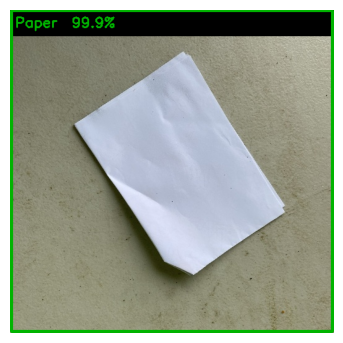

Cardboard: 0.1%  Glass: 0.0%  Metal: 0.0%  Paper: 99.9%  Plastic: 0.0%
TRUE: Paper | PREDICTED: Paper 



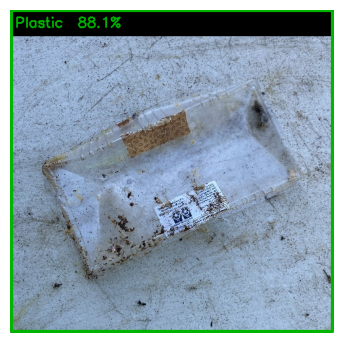

Cardboard: 8.0%  Glass: 3.7%  Metal: 0.0%  Paper: 0.1%  Plastic: 88.1%
TRUE: Plastic | PREDICTED: Plastic 



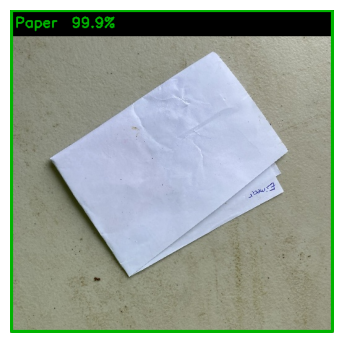

Cardboard: 0.0%  Glass: 0.0%  Metal: 0.0%  Paper: 99.9%  Plastic: 0.0%
TRUE: Paper | PREDICTED: Paper 



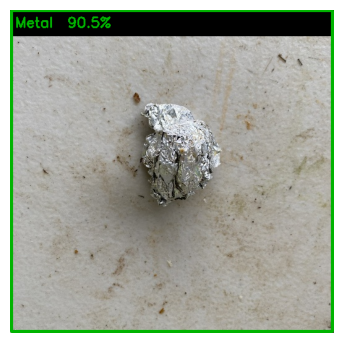

Cardboard: 2.2%  Glass: 1.3%  Metal: 90.5%  Paper: 2.2%  Plastic: 3.8%
TRUE: Metal | PREDICTED: Metal 



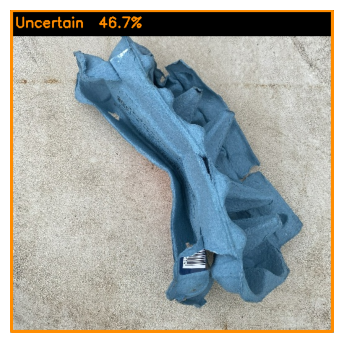

Cardboard: 13.4%  Glass: 8.5%  Metal: 2.4%  Paper: 46.7%  Plastic: 29.1%
TRUE: Cardboard | PREDICTED: Uncertain 



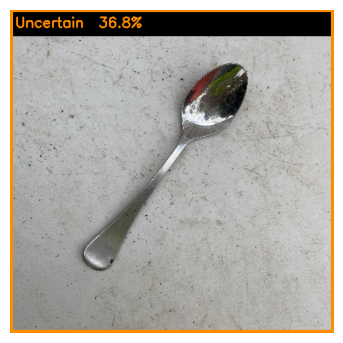

Cardboard: 2.2%  Glass: 32.9%  Metal: 28.0%  Paper: 0.1%  Plastic: 36.8%
TRUE: Metal | PREDICTED: Uncertain 



In [ ]:
def recognize(source, show=True):
    """source: image path or a BGR numpy array (e.g. a camera frame). Returns (label, confidence, annotated BGR image)."""
    bgr = cv2.imread(str(source)) if isinstance(source, (str, Path)) else source.copy()
    assert bgr is not None, f'Could not read {source}'
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)                       # preprocessing: BGR -> RGB
    x   = cv2.resize(rgb, IMG_SIZE, interpolation=cv2.INTER_AREA)    # preprocessing: resize 224x224
    p   = model.predict(x[None].astype('float32'), verbose=0)[0]     # model (scaling to [-1,1] is inside the model)
    k, conf = int(p.argmax()), float(p.max())                        # recognition
    # Below CONF_THRESH the model is not confident enough to commit to a class.
    label = CLASSES[k] if conf >= CONF_THRESH else 'Uncertain'
    out = bgr.copy(); h, w = out.shape[:2]
    color = (0, 180, 0) if label != 'Uncertain' else (0, 140, 255)
    cv2.rectangle(out, (0, 0), (w, max(34, h//12)), (0, 0, 0), -1)
    cv2.putText(out, f'{label}  {conf*100:.1f}%', (8, max(24, h//18)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w/700), color, 2)
    cv2.rectangle(out, (2, 2), (w-3, h-3), color, 3)                 # visual output
    if show:
        plt.figure(figsize=(4.2, 4.2)); plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
        print('  '.join(f'{c}: {v*100:.1f}%' for c, v in zip(CLASSES, p)))
    return label, conf, out

# demo on random images from the Testing set
for k in random.sample(range(len(p_te)), 6):
    label, conf, _ = recognize(p_te[k]); print('TRUE:', CLASSES[y_te[k]], '| PREDICTED:', label, '\n')

### 7a. Try your own / the instructor's images
Run the next cell and select one or more images (JPG/PNG). Each is classified and shown with its label and confidence.

Saving plastic-bottle.jpg to plastic-bottle.jpg
== plastic-bottle.jpg


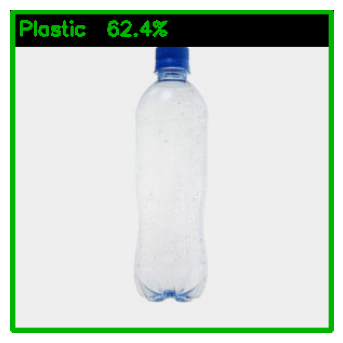

Cardboard: 2.6%  Glass: 34.6%  Metal: 0.3%  Paper: 0.1%  Plastic: 62.4%


In [ ]:
if IN_COLAB:
    from google.colab import files
    up = files.upload()
    for name in up: print('==', name); recognize(name)
else:
    print('Upload demo only runs in Colab. Call recognize("path/to/image.jpg") instead.')

### 7b. Live camera input (Colab webcam)
Run the cell, allow camera access in the browser, then click **Capture**. The photo goes through the same pipeline. Run the cell again for another photo.

In [10]:
def capture_from_webcam(filename='webcam.jpg', quality=0.9):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    js = Javascript('''
      async function takePhoto(quality) {
        const div = document.createElement('div');
        const btn = document.createElement('button'); btn.textContent = 'Capture'; div.appendChild(btn);
        const video = document.createElement('video'); video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div); div.appendChild(video); video.srcObject = stream; await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => btn.onclick = resolve);
        const canvas = document.createElement('canvas'); canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop(); div.remove();
        return canvas.toDataURL('image/jpeg', quality);
      }''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f: f.write(b64decode(data.split(',')[1]))
    return filename

if IN_COLAB:
    try:
        recognize(capture_from_webcam())
    except Exception as e:
        print('Webcam not available:', e)
else:
    print('Webcam demo only runs in Colab. For a local webcam use cv2.VideoCapture(0) and pass the frame to recognize().')

Webcam demo only runs in Colab. For a local webcam use cv2.VideoCapture(0) and pass the frame to recognize().


### 7c. Unseen-situation test (optional but recommended)
Take your own photos of the 5 classes under **different lighting, backgrounds and angles**, and put them in a folder with one sub-folder per class, e.g.

```
my_photos/
    Cardboard/  img1.jpg ...
    Glass/      ...
    Metal/      ...
    Paper/      ...
    Plastic/    ...
```
Zip the folder as `my_photos.zip`, set `MY_PHOTOS_ZIP` below and run the cell. The result is your accuracy on data that is truly unseen. If the file is not found, the cell is skipped.

In [11]:
MY_PHOTOS_ZIP = 'my_photos.zip'     # upload this file to the Colab file panel (left side) first

if os.path.exists(MY_PHOTOS_ZIP):
    mp = Path('my_photos'); shutil.rmtree(mp, ignore_errors=True)
    with zipfile.ZipFile(MY_PHOTOS_ZIP) as z: z.extractall(mp)
    ip, iy = [], []
    for d in mp.rglob('*'):
        if d.is_dir() and d.name in CLASSES:
            for f in images_in(d): ip.append(str(f)); iy.append(CLASSES.index(d.name))
    print(f'{len(ip)} unseen images found')
    if ip:
        ids = make_ds(ip, iy); pr = model.predict(ids, verbose=0).argmax(1)
        print(f'UNSEEN-IMAGE ACCURACY: {accuracy_score(iy, pr)*100:.2f}%')
        print(classification_report(iy, pr, labels=range(len(CLASSES)), target_names=CLASSES, zero_division=0))
else:
    print('No my_photos.zip found - skipping (optional).')

No my_photos.zip found - skipping (optional).


## Step 8. Save the model and a results summary
Export the trained model and class list, and write a `results.json` summary (test accuracy, macro F1, per-class F1) so the numbers quoted in the report come straight from this run.


In [17]:
model.save('waste_classifier.keras')
json.dump(CLASSES, open('class_names.json', 'w'))
results = {'classes': CLASSES, 'images_per_class': counts.to_dict(), 'split': {'train': len(p_tr), 'val': len(p_va), 'test': len(p_te)},
           'test_accuracy': round(float(test_acc), 4), 'macro_f1': round(rep['macro avg']['f1-score'], 4),
           'per_class_f1': {c: round(rep[c]['f1-score'], 4) for c in CLASSES}}
json.dump(results, open('results.json', 'w'), indent=2); print(json.dumps(results, indent=2))

print('\n=== COPY INTO THE REPORT / PRESENTATION ===')
print(f'Dataset: RealWaste subset, {len(CLASSES)} classes ({", ".join(CLASSES)}), {len(paths)} images')
print(f'Split: {len(p_tr)} training / {len(p_va)} validation / {len(p_te)} testing')
print(f'Model: MobileNetV2 (ImageNet transfer learning), input {IMG_SIZE[0]}x{IMG_SIZE[1]}')
print(f'Test accuracy: {test_acc*100:.2f}% | Macro F1: {rep["macro avg"]["f1-score"]:.4f}')
if IN_COLAB:
    from google.colab import files
    for f in ['waste_classifier.keras', 'class_names.json', 'results.json', 'confusion_matrix.png', 'split.csv']: files.download(f)

{
  "classes": [
    "Cardboard",
    "Glass",
    "Metal",
    "Paper",
    "Plastic"
  ],
  "images_per_class": {
    "Cardboard": 461,
    "Glass": 420,
    "Metal": 790,
    "Paper": 500,
    "Plastic": 921
  },
  "split": {
    "train": 2164,
    "val": 464,
    "test": 464
  },
  "test_accuracy": 0.8793,
  "macro_f1": 0.878,
  "per_class_f1": {
    "Cardboard": 0.8676,
    "Glass": 0.8682,
    "Metal": 0.8936,
    "Paper": 0.8875,
    "Plastic": 0.8731
  }
}

=== COPY INTO THE REPORT / PRESENTATION ===
Dataset: RealWaste subset, 5 classes (Cardboard, Glass, Metal, Paper, Plastic), 3092 images
Split: 2164 training / 464 validation / 464 testing
Model: MobileNetV2 (ImageNet transfer learning), input 224x224
Test accuracy: 87.93% | Macro F1: 0.8780


In [18]:
# --- Local reproduction addition (not part of the original Colab run) ---
# Also writes the same results dict and confusion-matrix figure into the repo's results/
# folder (not just this notebook's own working directory), so other docs that point to
# results/results.json have a real file to point to.
_repo_results_dir = os.environ.get('REPO_RESULTS_DIR')
if _repo_results_dir:
    from pathlib import Path as _Path
    import shutil as _shutil
    _rd = _Path(_repo_results_dir); _rd.mkdir(parents=True, exist_ok=True)
    _repo_results = dict(results)
    _repo_results['confusion_matrix'] = cm.tolist()
    _repo_results['classification_report'] = rep
    _repo_results['weighted_f1'] = round(rep['weighted avg']['f1-score'], 4)
    json.dump(_repo_results, open(_rd / 'results.json', 'w'), indent=2)
    if os.path.exists('confusion_matrix.png'):
        _shutil.copy('confusion_matrix.png', _rd / 'confusion_matrix.png')
    print('Wrote', _rd / 'results.json')


Wrote /home/jave/.treehouse/cv-object-sorting-7546a8/2/cv-object-sorting/results/results.json


### Notes for the report
* Put the **test accuracy, the classification report table and the confusion matrix** from Step 6 into your Results section.
* Say that the dataset is public (RealWaste), the model is a **pre-trained MobileNetV2** (ImageNet) fine-tuned by the group, and cite both (see References in the report). The project brief penalizes undocumented external datasets, code or models.
* If the instructor gives you test images, run `recognize("image.jpg")` (Step 7) live. Do not only show saved results.